# 1. **Entorno y GPU**
En Google Colab selecciona Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU T4 (o la GPU disponible). La selección se realiza desde la interfaz; la celda siguiente verifica la detección de CUDA.

In [1]:
import os, sys, platform, subprocess
import torch

DEVICE = 0 if torch.cuda.is_available() else -1
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("GPU disponible:", torch.cuda.is_available())
print("Hardware:", torch.cuda.get_device_name(0) if DEVICE == 0 else "CPU")
if DEVICE == 0:
    subprocess.run(["nvidia-smi"], check=False)
else:
    print("ADVERTENCIA: para la máxima puntuación en la rúbrica, activa la GPU antes de medir latencia.")

Python: 3.13.15
PyTorch: 2.11.0+cu130
GPU disponible: True
Hardware: Tesla T4


# **2. Instalación de dependencias**
El código usa PyTorch incluido en Colab. Si las versiones se cambian durante una ejecución, reinicia el entorno antes de continuar. transformers se limita a la rama 4.x para evitar cambios incompatibles de API.

In [2]:
%pip -q install "transformers>=4.46,<5" "huggingface_hub>=0.26,<1" "sentencepiece>=0.2,<0.3" "scikit-learn>=1.4,<2" "pandas>=2,<3" "matplotlib>=3.8,<4"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 120.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 50.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 126.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


# **3. Autenticación segura a Hugging Face Hub**
Los tres modelos son públicos, por lo que no es obligatorio proporcionar token para descargarlos. Si cuentas con uno, guárdalo en los Secrets de Colab bajo HF_TOKEN, sin pegarlo en el notebook. Puedes habilitar `LOGIN_INTERACTIVO=True` para iniciar sesión manualmente.

In [3]:
from huggingface_hub import login

TOKEN = os.environ.get("HF_TOKEN")
try:
    from google.colab import userdata
    TOKEN = TOKEN or userdata.get("HF_TOKEN")
except (ImportError, Exception):
    pass

LOGIN_INTERACTIVO = False
if TOKEN:
    login(token=TOKEN, add_to_git_credential=False)
    print("Sesión autenticada con token privado (no mostrado).")
elif LOGIN_INTERACTIVO:
    login(add_to_git_credential=False)
else:
    print("Modo público: acceso a modelos sin autenticación. No se guardan credenciales.")

Modo público: acceso a modelos sin autenticación. No se guardan credenciales.


# **4. Carga y validación del dataset**
Descarga resenas_dentales_simuladas.csv y súbelo cuando aparezca el selector de archivos. También funciona ejecutando el notebook desde la estructura del repositorio, donde el CSV está en data/.

In [4]:
from pathlib import Path
from collections import Counter
import pandas as pd

archivo = Path("data/resenas_dentales_simuladas.csv")
if not archivo.exists():
    archivo = Path("resenas_dentales_simuladas.csv")
if not archivo.exists():
    try:
        from google.colab import files
        print("Selecciona resenas_dentales_simuladas.csv en el diálogo:")
        files.upload()
    except ImportError as exc:
        raise FileNotFoundError("Coloca el CSV en ./data/ o en el directorio actual.") from exc
    archivo = Path("resenas_dentales_simuladas.csv")

assert archivo.exists(), f"No se localizó el archivo: {archivo}"
df = pd.read_csv(archivo, encoding="utf-8-sig", dtype={"id":str,"texto":str,"etiqueta":str,"tema":str,"origen":str})
required = {"id", "texto", "etiqueta", "tema", "origen"}
assert required.issubset(df.columns), f"Faltan columnas: {required-set(df.columns)}"
assert len(df) == 120 and df["id"].is_unique
assert not df[list(required)].isnull().any().any()
assert df["texto"].str.strip().str.casefold().is_unique
assert set(df["etiqueta"]) == {"POS", "NEG", "NEU"}
assert Counter(df["etiqueta"]) == {"POS":40, "NEG":40, "NEU":40}
assert (df["origen"] == "simulado").all()
print("Archivo:", archivo, "| Registros:", len(df))
print("Distribución por sentimiento:", dict(Counter(df["etiqueta"])))
display(df.head(6))
display(pd.crosstab(df["tema"], df["etiqueta"]))

Selecciona resenas_dentales_simuladas.csv en el diálogo:


Saving resenas_dentales_simuladas.csv to resenas_dentales_simuladas.csv
Archivo: resenas_dentales_simuladas.csv | Registros: 120
Distribución por sentimiento: {'POS': 40, 'NEG': 40, 'NEU': 40}


,id,texto,etiqueta,tema,origen
0,R001,Estoy contenta con el cambio en mis dientes; s...,POS,resultados,simulado
1,R002,Esperé demasiado para pasar y nadie me explicó...,NEG,tiempos,simulado
2,R003,"Pregunté por los pasos del procedimiento, pero...",NEG,explicaciones,simulado
3,R004,Las indicaciones posteriores fueron insuficien...,NEG,seguimiento,simulado
4,R005,No me explicaron bien las opciones y terminé c...,NEG,explicaciones,simulado
5,R006,"Estaba preocupado por el dolor, pero el proced...",POS,molestias,simulado


etiqueta,NEG,NEU,POS
tema,,,
atencion,4,4,4
citas,4,4,4
costos,4,4,4
explicaciones,4,4,4
instalaciones,4,4,4
molestias,4,4,4
pagos,4,4,4
resultados,4,4,4
seguimiento,4,4,4


# **5. Modelos y criterios técnicos**
Criterios: compatibilidad con tres clases, soporte de español, documentación [link text](https://)disponible, número de parámetros, licencia del repositorio, accuracy/F1 macro sobre los mismos ejemplos, y latencia de inferencia. Se usa la misma GPU, lote (BATCH_SIZE) y longitud máxima de entrada. El modelo ganador se decidirá tras observar las métricas, no por su popularidad.

In [5]:
import gc, json, time, statistics
import numpy as np
from transformers import pipeline, AutoConfig
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report

MODELOS = {
    "RoBERTuito": "pysentimiento/robertuito-sentiment-analysis",
    "XLM-RoBERTa": "cardiffnlp/twitter-xlm-roberta-base-sentiment",
    "DistilBERT": "lxyuan/distilbert-base-multilingual-cased-sentiments-student",
}
SEED = 42
BATCH_SIZE = 16
MAX_LENGTH = 128   # Compatible con la ventana posicional más corta de los tres candidatos.
N_REPETICIONES = 3 # Tres mediciones después de un calentamiento.
CLASES = ["NEG", "NEU", "POS"]
TEXTOS = df["texto"].tolist()
REALES = df["etiqueta"].tolist()

import random
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

def normalizar_etiqueta(etiqueta):
    mapa = {"positive":"POS", "pos":"POS", "positivo":"POS",
            "neutral":"NEU", "neu":"NEU", "neutro":"NEU",
            "negative":"NEG", "neg":"NEG", "negativo":"NEG"}
    key = str(etiqueta).strip().lower()
    if key not in mapa:
        raise ValueError(f"Etiqueta desconocida {etiqueta!r}. Revisar config.id2label del modelo.")
    return mapa[key]

print("Modelos:", MODELOS)
print("Normalización verificada:", [normalizar_etiqueta(s) for s in ["NEG", "neutral", "positive"]])

Modelos: {'RoBERTuito': 'pysentimiento/robertuito-sentiment-analysis', 'XLM-RoBERTa': 'cardiffnlp/twitter-xlm-roberta-base-sentiment', 'DistilBERT': 'lxyuan/distilbert-base-multilingual-cased-sentiments-student'}
Normalización verificada: ['NEG', 'NEU', 'POS']


# **6. Inferencia, accuracy, precision, recall, F1 y latencia**
Se mide tiempo de procesamiento en lote promedio por reseña, no latencia de una solicitud individual. La primera inferencia no se cronometra para reducir efectos del calentamiento. Los tiempos de descarga/carga se reportan por separado y no se suman a la inferencia. Cada modelo se descarga en secuencia y se libera de GPU antes del siguiente.

In [6]:
from huggingface_hub import model_info

resultados = []
predicciones = {}
metadatos = {}
Path("results").mkdir(exist_ok=True)

for nombre, modelo_id in MODELOS.items():
    print("\n" + "="*65 + f"\nEVALUANDO: {nombre}\n" + "="*65)
    config = AutoConfig.from_pretrained(modelo_id)
    print("Etiquetas originales:", config.id2label)
    for etiqueta in config.id2label.values():
        normalizar_etiqueta(etiqueta)  # fallar explícitamente si no tiene clases compatibles
    assert len(config.id2label) == 3

    try:
        info = model_info(modelo_id)
        card_data = info.card_data
        licencia = card_data.get("license", "no declarada") if isinstance(card_data, dict) else (getattr(card_data, "license", None) or "no declarada")
        revision = info.sha
    except Exception as e:
        licencia, revision = "pendiente de verificación", "no registrada"
        print("No se pudieron consultar metadatos del Hub:", str(e)[:180])

    inicio_carga = time.perf_counter()
    clasificador = pipeline(task="text-classification", model=modelo_id, tokenizer=modelo_id, device=DEVICE)
    tiempo_carga_s = time.perf_counter() - inicio_carga
    parametros_millones = sum(p.numel() for p in clasificador.model.parameters()) / 1e6
    print("Parámetros (M):", round(parametros_millones, 2))

    if DEVICE == 0:
        torch.cuda.reset_peak_memory_stats()
    # Calentamiento fuera de la medición
    _ = clasificador(TEXTOS[:BATCH_SIZE], batch_size=BATCH_SIZE, truncation=True, max_length=MAX_LENGTH)
    if DEVICE == 0:
        torch.cuda.synchronize()

    tiempos = []
    salida = None
    for repeticion in range(N_REPETICIONES):
        if DEVICE == 0: torch.cuda.synchronize()
        tic = time.perf_counter()
        salida = clasificador(TEXTOS, batch_size=BATCH_SIZE, truncation=True, max_length=MAX_LENGTH)
        if DEVICE == 0: torch.cuda.synchronize()
        tiempos.append(time.perf_counter() - tic)
        print(f"  Corrida {repeticion+1}: {tiempos[-1]:.3f} s")

    assert salida is not None and len(salida) == len(TEXTOS)
    y_pred = [normalizar_etiqueta(item["label"]) for item in salida]
    scores = [float(item["score"]) for item in salida]
    prec, rec, f1, _ = precision_recall_fscore_support(REALES, y_pred, labels=CLASES, average="macro", zero_division=0)
    prom_seg = statistics.mean(tiempos)
    pico_mem_mb = round(torch.cuda.max_memory_allocated() / 1024**2, 1) if DEVICE == 0 else None

    fila = {
        "modelo": nombre, "model_id": modelo_id,
        "accuracy": round(accuracy_score(REALES, y_pred), 5),
        "precision_macro": round(prec, 5), "recall_macro": round(rec, 5), "f1_macro": round(f1, 5),
        "latencia_lote_total_s": round(prom_seg, 5),
        "ms_por_resena_en_lote": round(1000 * prom_seg / len(TEXTOS), 4),
        "resenas_por_segundo": round(len(TEXTOS) / prom_seg, 3),
        "tiempo_carga_s": round(tiempo_carga_s, 3),
        "parametros_millones": round(parametros_millones, 2),
        "gpu_memoria_pico_mb": pico_mem_mb,
        "licencia_reportada_hub": licencia,
        "revision_hub": revision,
    }
    resultados.append(fila)
    predicciones[nombre] = y_pred
    metadatos[nombre] = {"model_id":modelo_id, "revision_hub":revision, "licencia":licencia, "tiempos_inferencia_s":tiempos}
    detalle = df.copy()
    detalle["prediccion"] = y_pred
    detalle["score_clase_predicha"] = scores  # confianza de clase predicha, NO accuracy
    detalle["correcta"] = detalle["etiqueta"] == detalle["prediccion"]
    detalle.to_csv(f"results/predicciones_{nombre.lower().replace('-', '_')}.csv", index=False, encoding="utf-8-sig")
    print("Accuracy:", round(fila["accuracy"], 3), "| F1 macro:", round(fila["f1_macro"], 3),
          "| ms/reseña en lote:", fila["ms_por_resena_en_lote"])
    print(classification_report(REALES, y_pred, labels=CLASES, zero_division=0))

    del clasificador, config, salida
    gc.collect()
    if DEVICE == 0:
        torch.cuda.empty_cache()

resumen = pd.DataFrame(resultados).sort_values(["f1_macro", "ms_por_resena_en_lote"], ascending=[False, True]).reset_index(drop=True)
resumen.to_csv("results/comparacion_modelos.csv", index=False, encoding="utf-8-sig")
display(resumen)


EVALUANDO: RoBERTuito


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/925 [00:00<?, ?B/s]

Etiquetas originales: {0: 'NEG', 1: 'NEU', 2: 'POS'}


model.safetensors:   0%|          | 0.00/435M [00:00<?, ?B/s]

...

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

Device set to use cuda:0


Parámetros (M): 135.33
  Corrida 1: 0.179 s
  Corrida 2: 0.123 s
  Corrida 3: 0.119 s
Accuracy: 0.475 | F1 macro: 0.409 | ms/reseña en lote: 1.168
              precision    recall  f1-score   support

         NEG       0.66      0.68      0.67        40
         NEU       0.00      0.00      0.00        40
         POS       0.45      0.75      0.56        40

    accuracy                           0.47       120
   macro avg       0.37      0.48      0.41       120
weighted avg       0.37      0.47      0.41       120



,modelo,model_id,accuracy,precision_macro,recall_macro,f1_macro,latencia_lote_total_s,ms_por_resena_en_lote,resenas_por_segundo,tiempo_carga_s,parametros_millones,gpu_memoria_pico_mb,licencia_reportada_hub,revision_hub
0,XLM-RoBERTa,cardiffnlp/twitter-xlm-roberta-base-sentiment,0.87500,0.90378,0.87500,0.87728,0.20273,1.6894,591.930,29.076,278.05,1086.8,no declarada,f2f1202b1bdeb07342385c3f807f9c07cd8f5cf8
1,RoBERTuito,pysentimiento/robertuito-sentiment-analysis,0.84167,0.88729,0.84167,0.84175,0.48571,4.0476,247.062,10.303,108.79,435.1,no declarada,a2cc0f67ebd705c55191e25a05ba23d885fcc09b
2,DistilBERT,lxyuan/distilbert-base-multilingual-cased-sent...,0.47500,0.36877,0.47500,0.40914,0.14016,1.1680,856.147,8.902,135.33,543.3,apache-2.0,cf991100d706c13c0a080c097134c05b7f436c45


# **7. Gráficas, matrices de confusión y análisis por tema**
Además del promedio macro se muestran errores por tipo de reseña. No interpretar el score de softmax como precisión demostrada: solo expresa la puntuación/confianza asignada a la clase predicha para un texto.

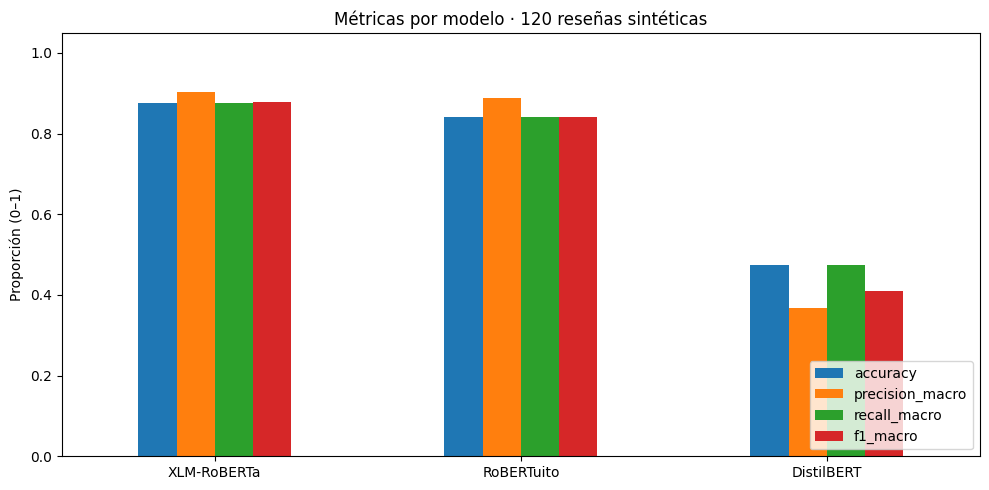

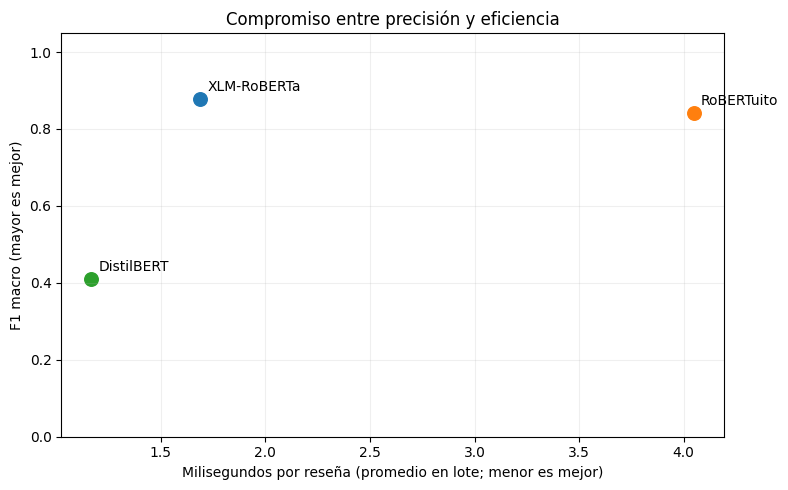

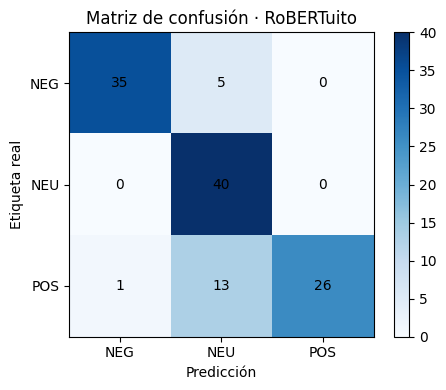

,accuracy_por_tema,count
tema,,
atencion,1.000,12
citas,0.833,12
costos,0.750,12
explicaciones,0.667,12
instalaciones,1.000,12
molestias,0.833,12
pagos,0.833,12
resultados,0.917,12
seguimiento,0.833,12


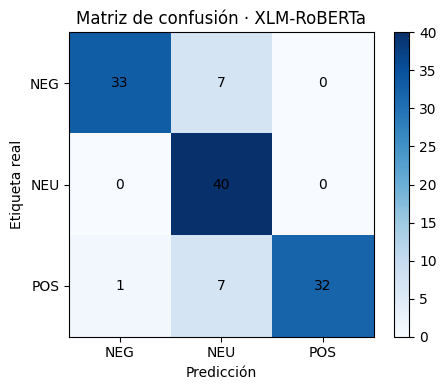

,accuracy_por_tema,count
tema,,
atencion,1.000,12
citas,0.833,12
costos,0.917,12
explicaciones,0.667,12
instalaciones,1.000,12
molestias,0.917,12
pagos,0.750,12
resultados,0.917,12
seguimiento,0.833,12


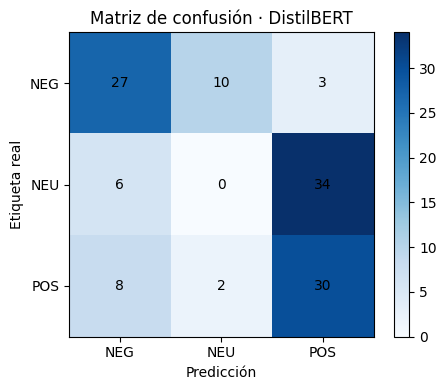

,accuracy_por_tema,count
tema,,
atencion,0.500,12
citas,0.417,12
costos,0.583,12
explicaciones,0.417,12
instalaciones,0.500,12
molestias,0.583,12
pagos,0.333,12
resultados,0.500,12
seguimiento,0.500,12


In [7]:
import matplotlib.pyplot as plt

# Desempeño global: tres métricas comparables entre modelos
plot_df = resumen.set_index("modelo")[["accuracy", "precision_macro", "recall_macro", "f1_macro"]]
ax = plot_df.plot(kind="bar", figsize=(10, 5), ylim=(0, 1.05), rot=0)
ax.set_title("Métricas por modelo · 120 reseñas sintéticas")
ax.set_ylabel("Proporción (0–1)"); ax.set_xlabel("")
ax.legend(loc="lower right"); plt.tight_layout()
plt.savefig("results/comparacion_metricas.png", dpi=180, bbox_inches="tight")
plt.show()

# Trade-off F1 vs tiempo
fig, ax = plt.subplots(figsize=(8, 5))
for _, fila in resumen.iterrows():
    ax.scatter(fila["ms_por_resena_en_lote"], fila["f1_macro"], s=95)
    ax.annotate(fila["modelo"], (fila["ms_por_resena_en_lote"], fila["f1_macro"]), xytext=(5, 6), textcoords="offset points")
ax.set_xlabel("Milisegundos por reseña (promedio en lote; menor es mejor)")
ax.set_ylabel("F1 macro (mayor es mejor)")
ax.set_title("Compromiso entre precisión y eficiencia")
ax.set_ylim(0, 1.05); ax.grid(alpha=0.2); plt.tight_layout()
plt.savefig("results/tradeoff_f1_latencia.png", dpi=180, bbox_inches="tight")
plt.show()

for nombre in MODELOS:
    matriz = confusion_matrix(REALES, predicciones[nombre], labels=CLASES)
    fig, ax = plt.subplots(figsize=(5, 4))
    im = ax.imshow(matriz, cmap="Blues", vmin=0)
    ax.set_xticks(range(3), CLASES); ax.set_yticks(range(3), CLASES)
    ax.set_xlabel("Predicción"); ax.set_ylabel("Etiqueta real")
    ax.set_title(f"Matriz de confusión · {nombre}")
    for i in range(3):
        for j in range(3): ax.text(j, i, str(matriz[i, j]), ha="center", va="center")
    fig.colorbar(im, ax=ax); plt.tight_layout()
    plt.savefig(f"results/matriz_{nombre.lower().replace('-', '_')}.png", dpi=170, bbox_inches="tight")
    plt.show()

    por_tema = df[["id", "tema", "etiqueta"]].copy()
    por_tema["correcto"] = por_tema["etiqueta"].eq(predicciones[nombre])
    display(por_tema.groupby("tema")["correcto"].agg(["mean", "count"]).rename(columns={"mean":"accuracy_por_tema"}).round(3))

# **8. Comparación e interpretación preliminar**
Los siguientes resultados se calculan únicamente después de ejecutar la inferencia. Esta clasificación propone un candidato por F1 macro, resolviendo empates por menor tiempo en lote. La elección operativa final debe considerar también errores relevantes, requisitos de negocio, tamaño/licencia del modelo y representatividad del dataset.

In [8]:
mejor = resumen.iloc[0]
print("Mejor candidato según F1 macro del corpus sintético:", mejor["modelo"])
print(f"F1 macro={mejor['f1_macro']:.3f}; accuracy={mejor['accuracy']:.3f}; "
      f"promedio por reseña en lote={mejor['ms_por_resena_en_lote']:.2f} ms")
print("ADVERTENCIA: benchmark exploratorio en texto simulado; no valida rendimiento en pacientes reales.")

# Muestra los ejemplos fallidos por modelo para redactar análisis cualitativo.
for nombre in MODELOS:
    errores = df[["id", "texto", "etiqueta", "tema"]].copy()
    errores["prediccion"] = predicciones[nombre]
    errores = errores[errores["etiqueta"] != errores["prediccion"]]
    print(f"\nErrores de {nombre}: {len(errores)} de {len(df)}")
    display(errores.head(8))
    errores.to_csv(f"results/errores_{nombre.lower().replace('-', '_')}.csv", index=False, encoding="utf-8-sig")

Mejor candidato según F1 macro del corpus sintético: XLM-RoBERTa
F1 macro=0.877; accuracy=0.875; promedio por reseña en lote=1.69 ms
ADVERTENCIA: benchmark exploratorio en texto simulado; no valida rendimiento en pacientes reales.

Errores de RoBERTuito: 19 de 120


,id,texto,etiqueta,tema,prediccion
2,R003,"Pregunté por los pasos del procedimiento, pero...",NEG,explicaciones,NEU
13,R014,Después del procedimiento me dieron seguimient...,POS,seguimiento,NEU
14,R015,Me entregaron un presupuesto claro y el cobro ...,POS,costos,NEU
17,R018,Me hablaron de cargos adicionales cuando el tr...,NEG,costos,NEU
37,R038,En la revisión posterior escucharon mis coment...,POS,seguimiento,NEU
39,R040,El comprobante llegó enseguida y el monto fue ...,POS,pagos,NEU
62,R063,Pude pagar con tarjeta y me explicaron las con...,POS,pagos,NEU
65,R066,El acabado del tratamiento superó mis expectat...,POS,resultados,NEU



Errores de XLM-RoBERTa: 15 de 120


,id,texto,etiqueta,tema,prediccion
2,R003,"Pregunté por los pasos del procedimiento, pero...",NEG,explicaciones,NEU
13,R014,Después del procedimiento me dieron seguimient...,POS,seguimiento,NEU
17,R018,Me hablaron de cargos adicionales cuando el tr...,NEG,costos,NEU
28,R029,La reserva fue sencilla; me enviaron la inform...,POS,citas,NEU
39,R040,El comprobante llegó enseguida y el monto fue ...,POS,pagos,NEU
62,R063,Pude pagar con tarjeta y me explicaron las con...,POS,pagos,NEU
67,R068,Respondieron incluso mis preguntas más básicas...,POS,explicaciones,NEU
77,R078,Me ofrecieron una modalidad de pago que al fin...,NEG,pagos,NEU



Errores de DistilBERT: 63 de 120


,id,texto,etiqueta,tema,prediccion
4,R005,No me explicaron bien las opciones y terminé c...,NEG,explicaciones,NEU
10,R011,El procedimiento se dividió en dos citas de di...,NEU,tiempos,POS
11,R012,El comprobante de pago se envió por correo ele...,NEU,pagos,POS
12,R013,No me convenció el aspecto de la restauración ...,NEG,resultados,NEU
15,R016,Pasé primero a la sala de espera y después al ...,NEU,instalaciones,POS
17,R018,Me hablaron de cargos adicionales cuando el tr...,NEG,costos,POS
18,R019,El odontólogo revisó el ajuste de la restaurac...,NEU,resultados,NEG
19,R020,Antes del procedimiento me preguntaron si tení...,NEU,molestias,NEG


# **9. Entorno reproducible, resultados y exportación**
El archivo comprimido de resultados se descargará desde Colab para usar las cifras y figuras en el documento Word. Los resultados no vienen precalculados; se generan al ejecutar la sesión.

In [9]:
import importlib.metadata as metadata
import shutil

manifest = {
    "fuente_dataset": "simulado; redacción manual para ejercicio académico",
    "numero_registros": len(df),
    "distribucion_clases": dict(Counter(REALES)),
    "modelo_seleccionado_preliminar": str(mejor["modelo"]),
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "transformers": metadata.version("transformers"),
    "huggingface_hub": metadata.version("huggingface_hub"),
    "sklearn": metadata.version("scikit-learn"),
    "gpu": torch.cuda.get_device_name(0) if DEVICE == 0 else "CPU",
    "device": DEVICE, "seed": SEED, "batch_size": BATCH_SIZE, "max_length": MAX_LENGTH,
    "repeticiones_cronometradas": N_REPETICIONES,
    "modelos": metadatos,
    "advertencia": "El rendimiento sobre reseñas simuladas no equivale a validación clínica o de producción."
}
with open("results/entorno_y_reproducibilidad.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, ensure_ascii=False, indent=2)

archivo_zip = shutil.make_archive("resultados_actividad4", "zip", root_dir="results")
print("Resultados guardados en:", archivo_zip)
print("Archivos:", sorted(p.name for p in Path("results").iterdir()))
try:
    from google.colab import files
    files.download(archivo_zip)
except ImportError:
    print("Ejecutando fuera de Colab: recupera el ZIP de la carpeta de trabajo.")

Resultados guardados en: /content/resultados_actividad4.zip
Archivos: ['comparacion_metricas.png', 'comparacion_modelos.csv', 'entorno_y_reproducibilidad.json', 'errores_distilbert.csv', 'errores_robertuito.csv', 'errores_xlm_roberta.csv', 'matriz_distilbert.png', 'matriz_robertuito.png', 'matriz_xlm_roberta.png', 'predicciones_distilbert.csv', 'predicciones_robertuito.csv', 'predicciones_xlm_roberta.csv', 'tradeoff_f1_latencia.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **10. Conclusiones parciales y limitaciones**
1. Los tres candidatos ejecutan la misma tarea sobre exactamente 120 ejemplos, con etiquetas normalizadas antes de calcular métricas.
2. Compara explícitamente F1 macro junto con accuracy, precision y recall. En un dataset balanceado, el F1 macro evidencia mejor diferencias por clase; revisa las matrices de confusión.
3. Describe si el candidato con mejor F1 macro también presenta menor latencia. El tiempo registrado es promedio por reseña procesada en lote, no respuesta de una única solicitud.
4. Analiza al menos dos errores del modelo recomendado; identifica negaciones, reseñas mixtas y expresiones técnicas odontológicas cuando aparezcan.
5. Limitaciones: dataset simulado y reducido, ausencia de anotadores independientes, dominio odontológico poco representado en los datos originales de entrenamiento de los modelos, posibles diferencias en tokenización y estilo, variabilidad del hardware/tiempos de Colab. Se necesita un conjunto real consentido y desidentificado antes de cualquier despliegue.
6. No se realizó fine-tuning: el experimento compara modelos preentrenados de forma controlada. El ajuste mínimo consiste en la armonización de etiquetas, límites de longitud, elección de lote y formateo de salidas.
Fuentes técnicas:
- https://huggingface.co/pysentimiento/robertuito-sentiment-analysis
- https://huggingface.co/cardiffnlp/twitter-xlm-roberta-base-sentiment
- https://huggingface.co/lxyuan/distilbert-base-multilingual-cased-sentiments-student
- https://huggingface.co/docs/transformers/main_classes/pipelines
- https://scikit-learn.org/stable/modules/model_evaluation.html